# PHẦN MỞ ĐẦU: TỔNG QUAN HỆ THỐNG VÀ PHƯƠNG PHÁP LUẬN NGHIÊN CỨU

---

## 1. Tính Cấp Thiết và Bối Cảnh Nghiên Cứu

Sự phát triển của Trí tuệ Nhân tạo (Artificial Intelligence - AI) trong những thập kỷ gần đây đã định hình lại các phương pháp giải quyết bài toán xử lý dữ liệu phức tạp. Từ những mô hình suy diễn dựa trên luật tĩnh ban đầu, lĩnh vực học máy đã chuyển dịch mạnh mẽ sang học thống kê (Statistical Machine Learning), học sâu (Deep Learning) với khả năng trích xuất đặc trưng tự động, và gần đây nhất là sự kết hợp giữa mô hình học sâu với Đồ thị tri thức (Knowledge Graph - KG) cùng cơ chế Tạo sinh tăng cường truy xuất (Retrieval-Augmented Generation - RAG).

Trong bối cảnh thực tiễn tại Việt Nam, nhu cầu phân tích và dự báo dữ liệu chuỗi thời gian tài chính (tiêu biểu là chỉ số chứng khoán **VN-Index** và **giá vàng SJC**), cũng như các bài toán phân loại chẩn đoán y tế và định giá bất động sản, đòi hỏi một hệ phương pháp luận có tính hệ thống cao, kết hợp chặt chẽ giữa toán học lý thuyết và kỹ thuật triển khai thực nghiệm.

Tiểu luận này được xây dựng nhằm cung cấp một lộ trình nghiên cứu và thực nghiệm toàn diện qua 5 chuyên đề trọng tâm:
1. **Lịch sử phát triển AI**: Phân tích các bước ngoặt từ Perceptron, các mùa đông AI đến sự trỗi dậy của Deep Learning.
2. **Kỹ thuật học máy cơ bản**: Cơ sở giải tích, đại số tuyến tính và tối ưu hóa của các mô hình hồi quy, phân loại kinh điển.
3. **Mạng nơ-ron tích chập (CNN)**: Bản chất giải tích của toán tử tích chập, pooling, và cơ chế trích xuất đặc trưng phân cấp.
4. **Mạng nơ-ron hồi quy (RNN - LSTM)**: Mô hình hóa chuỗi thời gian, giải quyết bài toán triệt tiêu đạo hàm qua cơ chế cổng, và thực nghiệm dự báo thị trường tài chính Việt Nam.
5. **Knowledge Graph và RAG**: Kiến trúc lai kết hợp tri thức biểu tượng có cấu trúc (KG) và truy xuất ngữ nghĩa (Vector Search) phục vụ bài toán hỏi đáp chuyên sâu có căn cứ nguồn.


## 2. Cơ Sở Toán Học Tổng Quát của Hệ Thống

Toàn bộ các mô hình được triển khai trong nghiên cứu đều dựa trên khung lý thuyết tối thiểu hóa rủi ro thực nghiệm (Empirical Risk Minimization - ERM) trong học có giám sát:

Giả sử tập dữ liệu huấn luyện gồm $N$ mẫu quan sát:
$$\mathcal{D} = \{(x_i, y_i)\}_{i=1}^N, \quad x_i \in \mathcal{X} \subset \mathbb{R}^d, \quad y_i \in \mathcal{Y}$$

Hàm mục tiêu tổng quát của mô hình tham số hóa bởi $\theta \in \mathbb{R}^p$ có dạng:
$$\min_{\theta} \mathcal{J}(\theta) = \frac{1}{N} \sum_{i=1}^N \mathcal{L}(y_i, f(x_i; \theta)) + \lambda \Omega(\theta)$$

Trong đó:
- $\mathcal{L}(y, \hat{y})$ là hàm mất mát đo lường sai khác giữa nhãn thực tế $y$ và giá trị dự báo $\hat{y} = f(x; \theta)$:
  - Đối với bài toán hồi quy (Hồi quy tuyến tính, dự báo giá nhà đất, dự báo chuỗi thời gian tài chính):
    $$\mathcal{L}_{\text{MSE}}(y, \hat{y}) = \frac{1}{2} (y - \hat{y})^2$$
  - Đối với bài toán phân loại nhị phân (Hồi quy Logistic, chẩn đoán y tế):
    $$\mathcal{L}_{\text{BCE}}(y, \hat{y}) = - \left[ y \log(\hat{y}) + (1 - y) \log(1 - \hat{y}) \right]$$
- $\Omega(\theta)$ là thành phần điều hòa (Regularization) nhằm kiểm soát độ phức tạp mô hình và chống hiện tượng quá khớp (Overfitting):
  - Điều hòa $L_2$ (Ridge): $\Omega(\theta) = \frac{1}{2} \|\theta\|_2^2 = \frac{1}{2} \sum_{j} \theta_j^2$
  - Điều hòa $L_1$ (Lasso): $\Omega(\theta) = \|\theta\|_1 = \sum_{j} |\theta_j|$
- $\lambda \ge 0$ là siêu tham số kiểm soát mức độ điều hòa.

Thuật toán tối ưu hóa cơ bản được sử dụng là Gradient Descent với quy tắc cập nhật:
$$\theta^{(t+1)} = \theta^{(t)} - \eta \nabla_\theta \mathcal{J}(\theta^{(t)})$$
với $\eta > 0$ là tốc độ học (learning rate).


In [1]:
# Thiết lập cấu hình hệ thống và thư viện thực thi
import sys
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

# Cấu hình giao diện biểu đồ theo chuẩn ấn phẩm khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 14

print(f"Môi trường thực thi: Python {platform.python_version()} on {platform.system()}")
print(f"Đường dẫn thư viện: {sys.executable}")


Môi trường thực thi: Python 3.14.6 on Windows
Đường dẫn thư viện: C:\Users\Admin\AppData\anaconda3\python.exe


### Sơ Đồ 1: Kiến Trúc Luồng Dữ Liệu và Lộ Trình Nghiên Cứu Tổng Thể
Sơ đồ sau mô tả toàn bộ chuỗi xử lý từ nguồn dữ liệu thô, các giai đoạn tiền xử lý, trích xuất đặc trưng qua các lớp kiến trúc (ML -> CNN -> RNN/LSTM -> KG+RAG) đến kết quả phân tích ứng dụng.


findfont: Failed to find font weight semibold, now using 700.


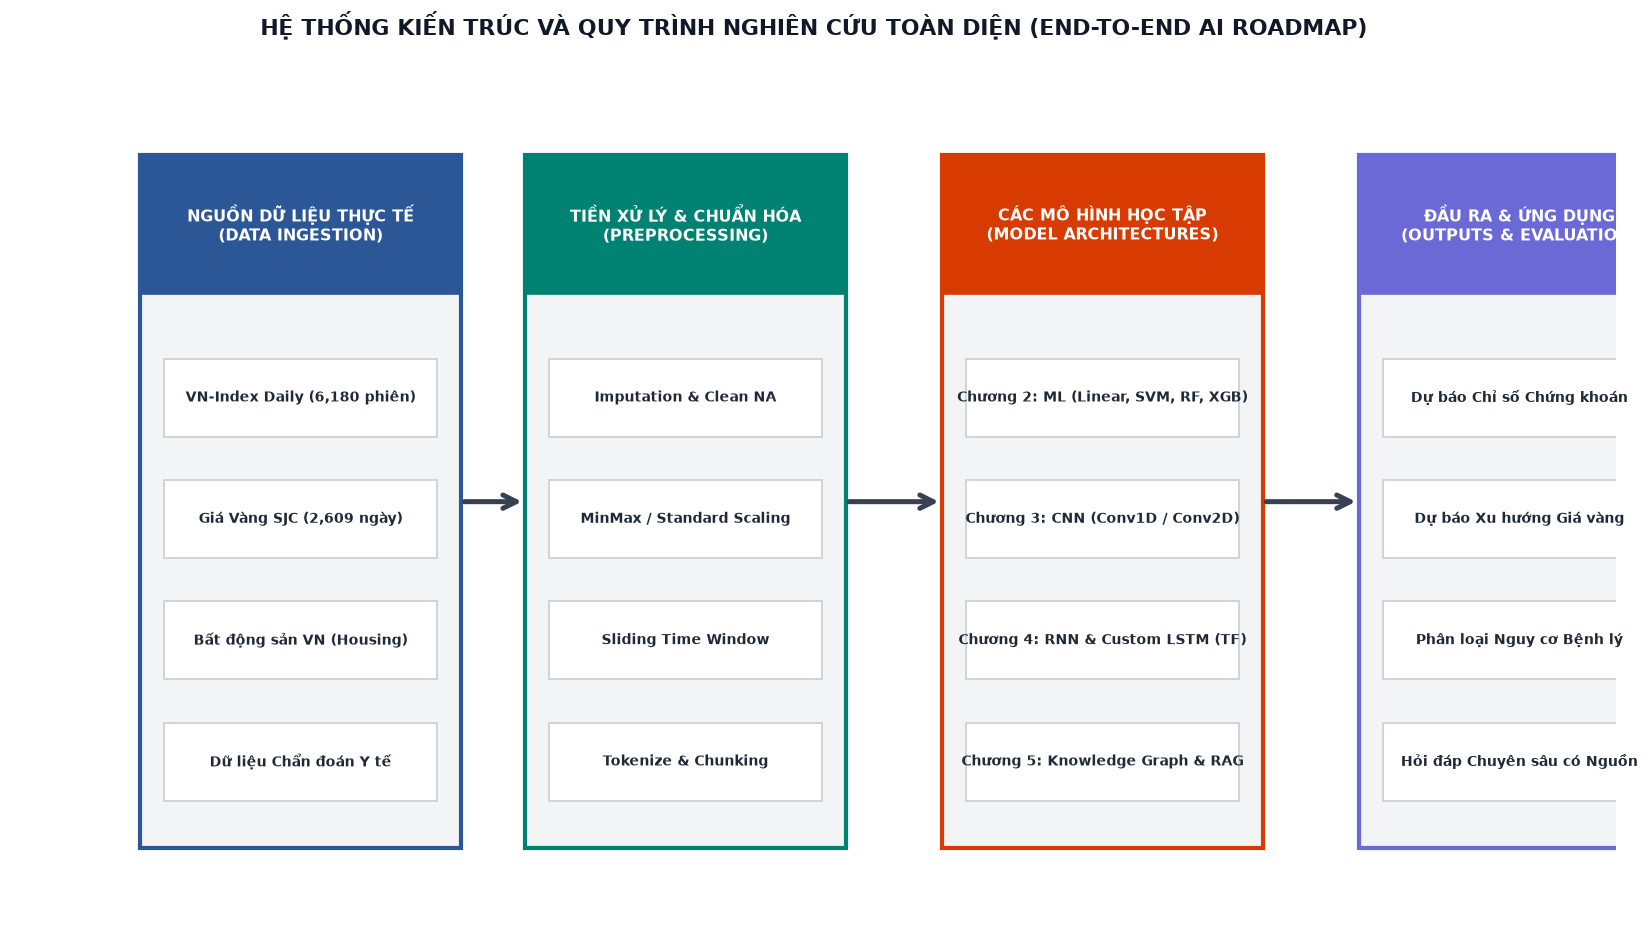

In [2]:
# Sơ đồ kiến trúc tổng thể toàn bộ tiểu luận
fig, ax = plt.subplots(figsize=(14, 8), dpi=120)
ax.axis('off')

stages = [
    {"name": "NGUỒN DỮ LIỆU THỰC TẾ\n(DATA INGESTION)", 
     "items": ["VN-Index Daily (6,180 phiên)", "Giá Vàng SJC (2,609 ngày)", "Bất động sản VN (Housing)", "Dữ liệu Chẩn đoán Y tế"],
     "x": 0.08, "color": "#2B5797"},
    {"name": "TIỀN XỬ LÝ & CHUẨN HÓA\n(PREPROCESSING)", 
     "items": ["Imputation & Clean NA", "MinMax / Standard Scaling", "Sliding Time Window", "Tokenize & Chunking"],
     "x": 0.32, "color": "#008272"},
    {"name": "CÁC MÔ HÌNH HỌC TẬP\n(MODEL ARCHITECTURES)", 
     "items": ["Chương 2: ML (Linear, SVM, RF, XGB)", "Chương 3: CNN (Conv1D / Conv2D)", "Chương 4: RNN & Custom LSTM (TF)", "Chương 5: Knowledge Graph & RAG"],
     "x": 0.58, "color": "#D83B01"},
    {"name": "ĐẦU RA & ỨNG DỤNG\n(OUTPUTS & EVALUATION)", 
     "items": ["Dự báo Chỉ số Chứng khoán", "Dự báo Xu hướng Giá vàng", "Phân loại Nguy cơ Bệnh lý", "Hỏi đáp Chuyên sâu có Nguồn"],
     "x": 0.84, "color": "#6B69D6"}
]

box_width = 0.20
box_height = 0.80

for stage in stages:
    # Outer box
    rect = plt.Rectangle((stage['x'], 0.1), box_width, box_height, 
                         facecolor='#F3F4F6', edgecolor=stage['color'], linewidth=2.5,
                         transform=ax.transAxes, zorder=2)
    ax.add_patch(rect)
    
    # Header box
    header_rect = plt.Rectangle((stage['x'], 0.74), box_width, 0.16,
                                facecolor=stage['color'], edgecolor=stage['color'],
                                transform=ax.transAxes, zorder=3)
    ax.add_patch(header_rect)
    
    # Header text
    ax.text(stage['x'] + box_width/2, 0.82, stage['name'],
            ha='center', va='center', color='white', weight='bold', fontsize=9.5,
            transform=ax.transAxes, zorder=4)
    
    # Items
    for idx, item in enumerate(stage['items']):
        y_pos = 0.62 - idx * 0.14
        item_box = plt.Rectangle((stage['x'] + 0.015, y_pos - 0.045), box_width - 0.03, 0.09,
                                 facecolor='white', edgecolor='#D1D5DB', linewidth=1.2,
                                 transform=ax.transAxes, zorder=3)
        ax.add_patch(item_box)
        ax.text(stage['x'] + box_width/2, y_pos, item,
                ha='center', va='center', color='#1F2937', fontsize=8.5, weight='semibold',
                transform=ax.transAxes, zorder=4)

# Connecting arrows
for i in range(len(stages) - 1):
    x_start = stages[i]['x'] + box_width
    x_end = stages[i+1]['x']
    ax.annotate('', xy=(x_end, 0.5), xytext=(x_start, 0.5),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle="->", color="#374151", lw=3.0, mutation_scale=20),
                zorder=5)

ax.set_title("HỆ THỐNG KIẾN TRÚC VÀ QUY TRÌNH NGHIÊN CỨU TOÀN DIỆN (END-TO-END AI ROADMAP)", 
             fontsize=13, weight='bold', pad=20, color='#111827')
plt.show()


### Sơ Đồ 2: Cây Phân Loại Các Phương Pháp Trí Tuệ Nhân Tạo
Sơ đồ sau cấu trúc hóa các phương pháp nghiên cứu theo phân cấp: Trí tuệ Nhân tạo tổng thể, Học máy truyền thống, Học sâu (Deep Learning) và Hệ thống Tri thức lai.


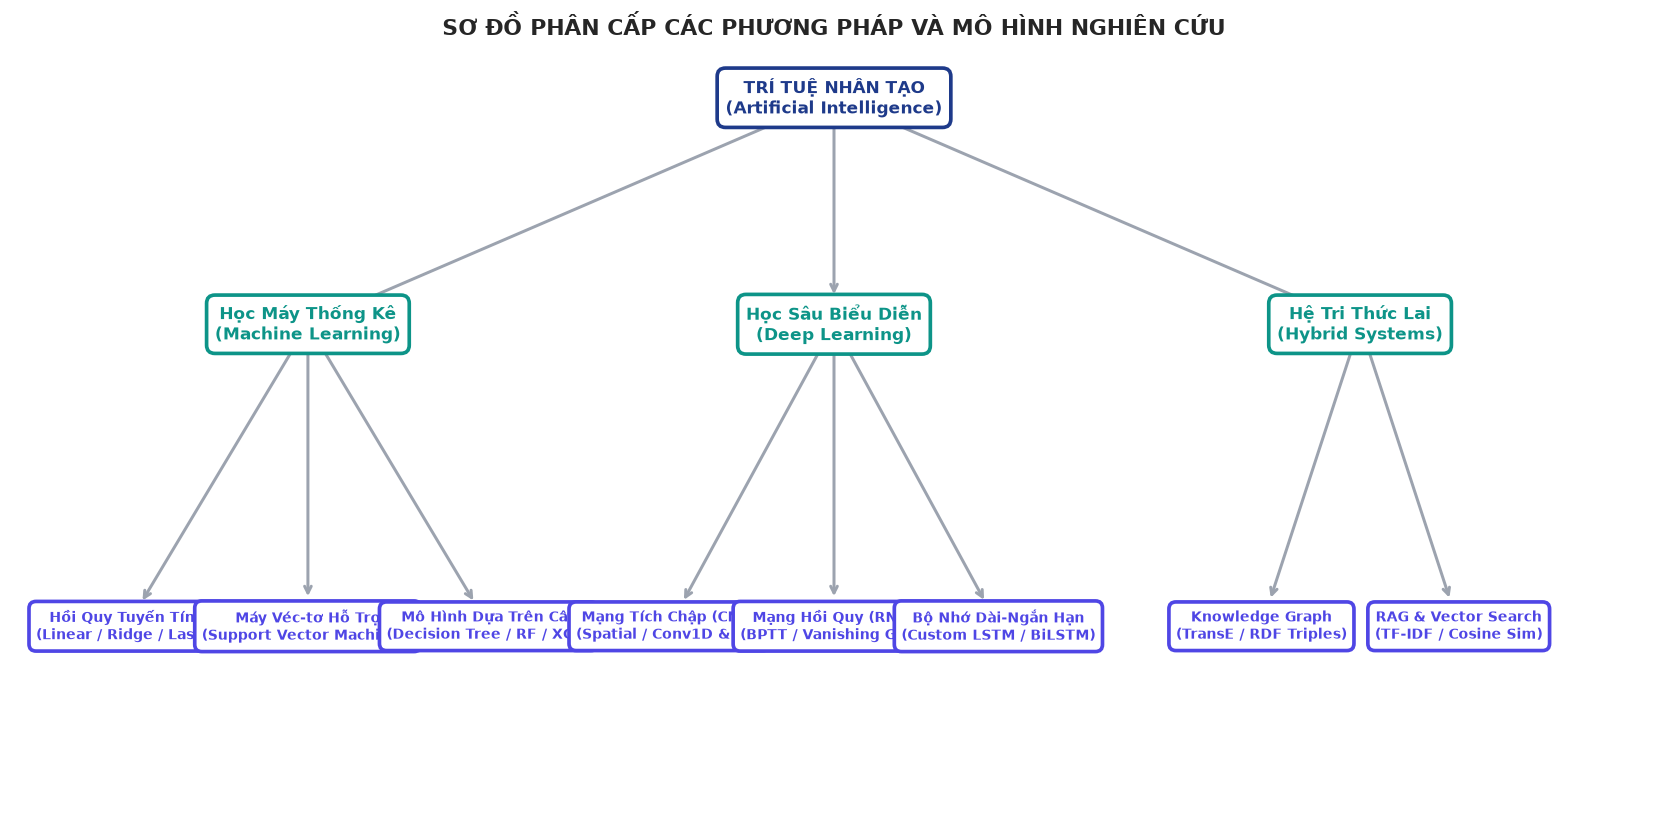

In [3]:
# Cây phân loại mô hình (Model Taxonomy)
G = nx.DiGraph()

nodes = {
    "AI": ("TRÍ TUỆ NHÂN TẠO\n(Artificial Intelligence)", 0),
    "ML": ("Học Máy Thống Kê\n(Machine Learning)", 1),
    "DL": ("Học Sâu Biểu Diễn\n(Deep Learning)", 1),
    "Hybrid": ("Hệ Tri Thức Lai\n(Hybrid Systems)", 1),
    "Reg": ("Hồi Quy Tuyến Tính\n(Linear / Ridge / Lasso)", 2),
    "SVM": ("Máy Véc-tơ Hỗ Trợ\n(Support Vector Machines)", 2),
    "Tree": ("Mô Hình Dựa Trên Cây\n(Decision Tree / RF / XGB)", 2),
    "CNN": ("Mạng Tích Chập (CNN)\n(Spatial / Conv1D & 2D)", 2),
    "RNN": ("Mạng Hồi Quy (RNN)\n(BPTT / Vanishing Grad)", 2),
    "LSTM": ("Bộ Nhớ Dài-Ngắn Hạn\n(Custom LSTM / BiLSTM)", 2),
    "KG": ("Knowledge Graph\n(TransE / RDF Triples)", 2),
    "RAG": ("RAG & Vector Search\n(TF-IDF / Cosine Sim)", 2)
}

edges = [
    ("AI", "ML"), ("AI", "DL"), ("AI", "Hybrid"),
    ("ML", "Reg"), ("ML", "SVM"), ("ML", "Tree"),
    ("DL", "CNN"), ("DL", "RNN"), ("DL", "LSTM"),
    ("Hybrid", "KG"), ("Hybrid", "RAG")
]

pos = {
    "AI": (0.5, 0.95),
    "ML": (0.18, 0.65), "DL": (0.5, 0.65), "Hybrid": (0.82, 0.65),
    "Reg": (0.07, 0.25), "SVM": (0.18, 0.25), "Tree": (0.29, 0.25),
    "CNN": (0.40, 0.25), "RNN": (0.50, 0.25), "LSTM": (0.60, 0.25),
    "KG": (0.76, 0.25), "RAG": (0.88, 0.25)
}

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)
ax.axis('off')

# Draw edges
for u, v in edges:
    ax.annotate('', xy=pos[v], xytext=pos[u],
                xycoords='data', textcoords='data',
                arrowprops=dict(arrowstyle="->", color="#9CA3AF", lw=1.8, shrinkA=18, shrinkB=18))

# Node colors by level
level_colors = {0: "#1E3A8A", 1: "#0D9488", 2: "#4F46E5"}

for node_id, (label, level) in nodes.items():
    x, y = pos[node_id]
    color = level_colors[level]
    bbox_props = dict(boxstyle="round,pad=0.5", fc="#FFFFFF", ec=color, lw=2.2)
    ax.text(x, y, label, ha="center", va="center", color=color,
            fontsize=8.5 if level == 2 else 10, weight="bold", bbox=bbox_props)

ax.set_title("SƠ ĐỒ PHÂN CẤP CÁC PHƯƠNG PHÁP VÀ MÔ HÌNH NGHIÊN CỨU", fontsize=13, weight='bold', pad=15)
plt.show()


## 3. Khung Đánh Giá Hiệu Năng Mô Hình (Evaluation Metrics)

Hệ thống đánh giá được chuẩn hóa theo từng nhóm bài toán:

### 3.1. Bài toán Hồi quy và Dự báo Chuỗi Thời Gian
- **Sai số bình phương trung bình căn bậc hai (RMSE)**:
  $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
- **Sai số tuyệt đối trung bình (MAE)**:
  $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
- **Hệ số xác định ($R^2$ Score)**:
  $$R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$

### 3.2. Bài toán Phân loại
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision**: $\frac{TP}{TP + FP}$, **Recall**: $\frac{TP}{TP + FN}$
- **F1-Score**: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$
- **ROC-AUC**: Diện tích dưới đường cong ROC biểu thị tương quan giữa True Positive Rate và False Positive Rate.

### 3.3. Bài toán Truy xuất Tri thức (KG + RAG)
- **Hit Rate @ $k$**: Tỷ lệ câu hỏi mà tài liệu đích nằm trong Top-$k$ kết quả truy xuất:
  $$\text{HitRate@}k = \frac{1}{|Q|} \sum_{q \in Q} \mathbb{I}(\text{rank}(d_q^*) \le k)$$
- **Mean Reciprocal Rank (MRR)**:
  $$\text{MRR} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$


C:\Users\Admin\AppData\Local\Temp\ipykernel_9284\3674262442.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(df_meta['Tên Tệp'], rotation=25, ha='right')


findfont: Failed to find font weight semibold, now using 700.


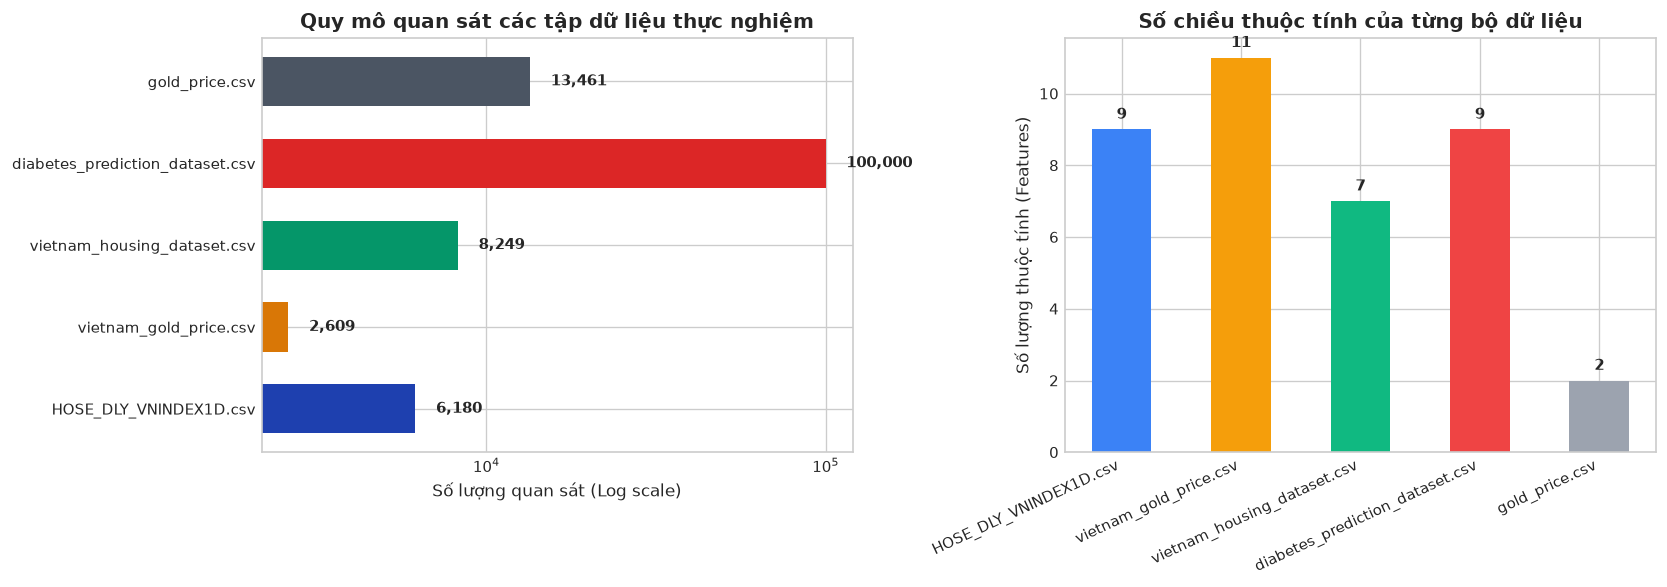

                        Tên Tệp                Miền Ứng Dụng  Số Mẫu  Số Thuộc Tính                     Mục Tiêu
         HOSE_DLY_VNINDEX1D.csv Cổ phiếu Việt Nam (VN-Index)    6180              9  Dự báo giá đóng cửa (Close)
         vietnam_gold_price.csv        Giá vàng SJC Việt Nam    2609             11    Dự báo giá bán SJC (Sell)
    vietnam_housing_dataset.csv        Bất động sản Việt Nam    8249              7     Định giá nhà đất (Price)
diabetes_prediction_dataset.csv               Chẩn đoán y tế  100000              9 Phân loại nguy cơ tiểu đường
                 gold_price.csv    Giá vàng thế giới lịch sử   13461              2    Đối sánh xu hướng quốc tế


In [4]:
# Tổng hợp đặc tả dữ liệu thực nghiệm trong hệ thống
datasets_info = [
    {"Tên Tệp": "HOSE_DLY_VNINDEX1D.csv", "Miền Ứng Dụng": "Cổ phiếu Việt Nam (VN-Index)", "Số Mẫu": 6180, "Số Thuộc Tính": 9, "Mục Tiêu": "Dự báo giá đóng cửa (Close)"},
    {"Tên Tệp": "vietnam_gold_price.csv", "Miền Ứng Dụng": "Giá vàng SJC Việt Nam", "Số Mẫu": 2609, "Số Thuộc Tính": 11, "Mục Tiêu": "Dự báo giá bán SJC (Sell)"},
    {"Tên Tệp": "vietnam_housing_dataset.csv", "Miền Ứng Dụng": "Bất động sản Việt Nam", "Số Mẫu": 8249, "Số Thuộc Tính": 7, "Mục Tiêu": "Định giá nhà đất (Price)"},
    {"Tên Tệp": "diabetes_prediction_dataset.csv", "Miền Ứng Dụng": "Chẩn đoán y tế", "Số Mẫu": 100000, "Số Thuộc Tính": 9, "Mục Tiêu": "Phân loại nguy cơ tiểu đường"},
    {"Tên Tệp": "gold_price.csv", "Miền Ứng Dụng": "Giá vàng thế giới lịch sử", "Số Mẫu": 13461, "Số Thuộc Tính": 2, "Mục Tiêu": "Đối sánh xu hướng quốc tế"}
]

df_meta = pd.DataFrame(datasets_info)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Bar chart: Sample Counts
bars = ax1.barh(df_meta['Tên Tệp'], df_meta['Số Mẫu'], color=['#1E40AF', '#D97706', '#059669', '#DC2626', '#4B5563'], height=0.6)
ax1.set_xscale('log')
ax1.set_xlabel('Số lượng quan sát (Log scale)')
ax1.set_title('Quy mô quan sát các tập dữ liệu thực nghiệm', weight='bold')
for bar in bars:
    w = bar.get_width()
    ax1.text(w * 1.15, bar.get_y() + bar.get_height()/2, f"{int(w):,}", va='center', fontsize=9, weight='semibold')

# Feature Counts
bars2 = ax2.bar(df_meta['Tên Tệp'], df_meta['Số Thuộc Tính'], color=['#3B82F6', '#F59E0B', '#10B981', '#EF4444', '#9CA3AF'], width=0.5)
ax2.set_ylabel('Số lượng thuộc tính (Features)')
ax2.set_title('Số chiều thuộc tính của từng bộ dữ liệu', weight='bold')
ax2.set_xticklabels(df_meta['Tên Tệp'], rotation=25, ha='right')
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.3, str(int(h)), ha='center', fontsize=9, weight='semibold')

plt.tight_layout()
plt.show()

# Hiển thị bảng mô tả chi tiết
print(df_meta.to_string(index=False))


## 4. Cấu Trúc Các Chương Tiếp Theo

Toàn bộ báo cáo tiểu luận được bố cục thành các tài liệu notebook độc lập, có thể tái lập thực nghiệm hoàn chỉnh:
- **`01_Chuong1_Lich_Su_Phat_Trien_AI.ipynb`**: Phân tích lịch sử từ Turing, Perceptron, hai mùa đông AI đến Deep Learning; lập trình mô phỏng Perceptron và ranh giới phân tách XOR.
- **`02_Chuong2_Cac_Ky_Thuat_ML_Co_Ban.ipynb`**: Phân tích và huấn luyện đối sánh các thuật toán học máy kinh điển (Linear, Logistic, SVM, Decision Tree, Random Forest, XGBoost) trên tập dữ liệu y tế và bất động sản Việt Nam.
- **`03_Chuong3_CNN.ipynb`**: Lý thuyết toán học phép tích chập, cài đặt Conv1D và Conv2D từ đầu bằng NumPy, xây dựng mô hình CNN hoàn chỉnh với TensorFlow.
- **`04_Chuong4_RNN_LSTM.ipynb`**: Lý thuyết chuỗi thời gian, cài đặt Custom TensorFlow Layer (SimpleRNN, Vanilla LSTM, Stacked LSTM, Bidirectional LSTM) và thực nghiệm dự báo chỉ số VN-Index cùng giá vàng Việt Nam SJC.
- **`05_Chuong5_Knowledge_Graph_va_RAG.ipynb`**: Xây dựng hệ thống hỏi đáp lai kết hợp Đồ thị tri thức (NetworkX) và RAG (TF-IDF + Cosine Similarity) với chế độ trích xuất có căn cứ nguồn trên dữ liệu đa miền.
